# 接触对象：内部接触量与链尺寸

接触数为唯一残基对数；Rg为质量加权链尺寸，单位nm。前图均值先帧内链平均再对有效帧平均，误差为块SEM。
散点中浅点是逐链逐帧观测，菱形是帧内均值；它们有时间和链间相关，不作独立重复。
中心链身份可逐帧变化；接触与Rg必须按同帧同链对应。关联不证明因果或稳定折叠。

在首个代码单元选择OBJECT：central_chain为每帧中心链，dense_chains为全部浓相链。


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "simulations.yaml").is_file())
sys.path.insert(0, str(ROOT))
from common import inputs
from common import results as files

SELECTED = None
OBJECT = "central_chain"  # central_chain / dense_chains
RESULTS_ROOT = ROOT / "03_results"
SIMULATIONS = inputs.select_simulations(ROOT / "simulations.yaml", SELECTED)
RESULTS = {s["id"]: files.completed(RESULTS_ROOT / s["id"] / "02_contacts/01_intra" / OBJECT) for s in SIMULATIONS}
SOURCES = {name: files.read_json(path / "metadata.json") for name, path in RESULTS.items()}
COLORS = {name: plt.get_cmap("tab10")(i % 10) for i, name in enumerate(RESULTS)}
FIGURES = ROOT / "05_plot/02_contacts/01_intra/figures" / OBJECT
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(
    {
        "font.size": 9,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
        "legend.frameon": False,
    }
)


def export(fig, name):
    for key, path in RESULTS.items():
        files.completed(path)
        if files.read_json(path / "metadata.json") != SOURCES[key]:
            raise ValueError("Results changed; restart notebook")
    for ext in ("png", "pdf", "svg"):
        fig.savefig(FIGURES / f"{name}.{ext}", dpi=300, bbox_inches="tight")
    files.write_json(FIGURES / f"{name}.sources.json", SOURCES)


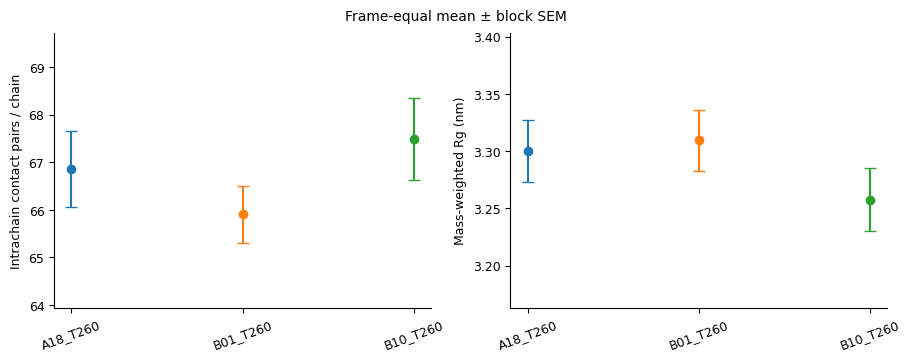

,simulation_id,contact_count_mean_frames,contact_count_std_frames,contact_count_count_frames,rg_nm_mean_frames,rg_nm_std_frames,rg_nm_count_frames,largest_component_fraction_mean_frames,largest_component_fraction_std_frames,largest_component_fraction_count_frames,...,contact_count_sem_blocks,rg_nm_std_blocks,rg_nm_count_blocks,rg_nm_sem_blocks,largest_component_fraction_std_blocks,largest_component_fraction_count_blocks,largest_component_fraction_sem_blocks,global_efficiency_std_blocks,global_efficiency_count_blocks,global_efficiency_sem_blocks
0,A18_T260,66.864000,19.789686,750,3.300322,0.725788,750,0.171018,0.093678,750,...,0.799069,0.104378,15,0.026950,0.009880,15,0.002551,0.001577,15,0.000407
1,B01_T260,65.906667,20.048721,750,3.309412,0.738130,750,0.167152,0.086210,750,...,0.595541,0.103516,15,0.026728,0.015083,15,0.003894,0.001568,15,0.000405
2,B10_T260,67.481333,20.322409,750,3.257619,0.747100,750,0.184041,0.096496,750,...,0.857512,0.107304,15,0.027706,0.015617,15,0.004032,0.002007,15,0.000518


In [2]:
summary = pd.concat([pd.read_csv(p / "summary.csv") for p in RESULTS.values()], ignore_index=True)


def mean_comparison(metrics, filename):
    fig, axes = plt.subplots(
        1, len(metrics), figsize=(4.5 * len(metrics), 3.5), squeeze=False, constrained_layout=True
    )
    for ax, (metric, label) in zip(axes[0], metrics.items()):
        bounds = []
        for x, name in enumerate(RESULTS):
            row = summary[summary.simulation_id.eq(name)].iloc[0]
            value, sem = row[metric + "_mean_frames"], row[metric + "_sem_blocks"]
            if np.isfinite(value):
                err = sem if np.isfinite(sem) else 0
                bounds.extend((value - err, value + err))
                ax.errorbar(x, value, yerr=err, fmt="o", capsize=4, color=COLORS[name])
        if bounds:
            pad = max((max(bounds) - min(bounds)) * 0.15, abs(max(bounds)) * 0.02, 1e-9)
            ax.set_ylim(max(0, min(bounds) - pad), max(bounds) + pad)
        ax.set(xticks=range(len(RESULTS)), xticklabels=list(RESULTS), ylabel=label)
        ax.tick_params(axis="x", labelrotation=20)
    fig.suptitle("Frame-equal mean ± block SEM", fontsize=10)
    export(fig, filename)
    plt.show()


mean_comparison(
    {"contact_count": "Intrachain contact pairs / chain", "rg_nm": "Mass-weighted Rg (nm)"},
    "contacts_rg_comparison",
)
display(summary)


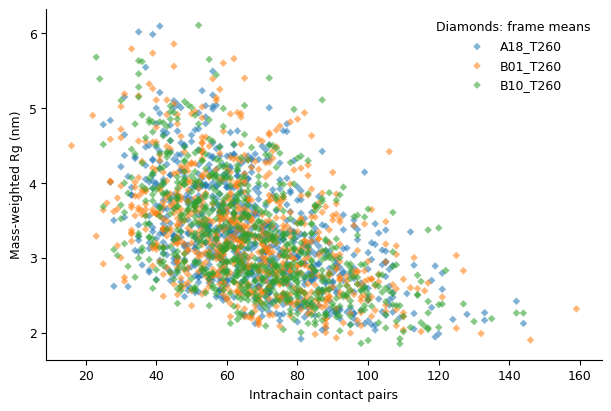

In [3]:
fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
for name, path in RESULTS.items():
    rows = pd.read_csv(path / "chain_contacts.csv.gz")
    means = pd.read_csv(path / "frame_means.csv")
    ax.scatter(
        rows.contact_count,
        rows.rg_nm,
        s=5,
        alpha=0.05,
        color=COLORS[name],
        edgecolors="none",
        rasterized=True,
    )
    ax.scatter(
        means.contact_count,
        means.rg_nm,
        s=15,
        alpha=0.55,
        color=COLORS[name],
        marker="D",
        label=name,
        edgecolors="none",
    )
ax.set(xlabel="Intrachain contact pairs", ylabel="Mass-weighted Rg (nm)")
ax.legend(title="Diamonds: frame means")
export(fig, "contacts_vs_rg")
plt.show()
